In [48]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [60]:
%cd '/content/drive/My Drive/filoger/project'

/content/drive/My Drive/filoger/project


In [61]:
DATA_PATH = 'Dataset_BUSI_with_GT'

In [51]:
# Import Necessary libraries
import os
import pandas as pd
import shutil
import numpy as np
import matplotlib.pyplot as plt
import random
import seaborn as sns
import albumentations as A
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Activation, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from PIL import Image
from sklearn.utils import class_weight
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications import MobileNetV3Small
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import regularizers

# **Check DataSet**

In [ ]:
#classes names
import numpy as np
import os

unique_classes = []
for path in os.listdir(DATA_PATH):
  unique_classes.append(path)

print(unique_classes)

['normal', 'benign', 'malignant']


In [ ]:
images = []
masks = []
labels = []
for folder in os.listdir(DATA_PATH):
  class_path = os.path.join(DATA_PATH, folder)
  for img in os.listdir(class_path):
    if '_mask' not in img:
      img_path = os.path.join(class_path, img)
      mask_path = img_path.replace('.png', '_mask.png')
      if os.path.exists(mask_path):
        images.append(img_path)
        masks.append(mask_path)
        labels.append(folder)

print('Count Images: ', len(images))
print('Count Masks: ', len(masks))
print('Count Labels: ', len(labels))

df = pd.DataFrame({'images_path': images,
                   'masks_path': masks,
                   'labels': labels})


print(df)

Count Images:  780
Count Masks:  780
Count Labels:  780
                                           images_path  \
0         Dataset_BUSI_with_GT/normal/normal (121).png   
1         Dataset_BUSI_with_GT/normal/normal (125).png   
2         Dataset_BUSI_with_GT/normal/normal (111).png   
3         Dataset_BUSI_with_GT/normal/normal (106).png   
4         Dataset_BUSI_with_GT/normal/normal (107).png   
..                                                 ...   
775  Dataset_BUSI_with_GT/malignant/malignant (86).png   
776  Dataset_BUSI_with_GT/malignant/malignant (97).png   
777  Dataset_BUSI_with_GT/malignant/malignant (98).png   
778  Dataset_BUSI_with_GT/malignant/malignant (96).png   
779  Dataset_BUSI_with_GT/malignant/malignant (99).png   

                                            masks_path     labels  
0    Dataset_BUSI_with_GT/normal/normal (121)_mask.png     normal  
1    Dataset_BUSI_with_GT/normal/normal (125)_mask.png     normal  
2    Dataset_BUSI_with_GT/normal/normal (11

In [ ]:
images = []
masks = []
labels = []
for folder in os.listdir(DATA_PATH):
  class_path = os.path.join(DATA_PATH, folder)
  for img in os.listdir(class_path):
    if '_mask' not in img:
      img_path = os.path.join(class_path, img)
      mask_path = img_path.replace('.png', '_mask_1.png')
      if os.path.exists(mask_path):
        images.append(img_path)
        masks.append(mask_path)
        labels.append(folder)

print('Count Images: ', len(images))
print('Count Masks: ', len(masks))
print('Count Labels: ', len(labels))

df = pd.DataFrame({'images_path': images,
                   'masks_path': masks,
                   'labels': labels})


print(df)

Count Images:  17
Count Masks:  17
Count Labels:  17
                                          images_path  \
0        Dataset_BUSI_with_GT/benign/benign (100).png   
1        Dataset_BUSI_with_GT/benign/benign (163).png   
2        Dataset_BUSI_with_GT/benign/benign (181).png   
3        Dataset_BUSI_with_GT/benign/benign (173).png   
4        Dataset_BUSI_with_GT/benign/benign (195).png   
5         Dataset_BUSI_with_GT/benign/benign (25).png   
6        Dataset_BUSI_with_GT/benign/benign (346).png   
7        Dataset_BUSI_with_GT/benign/benign (315).png   
8        Dataset_BUSI_with_GT/benign/benign (424).png   
9          Dataset_BUSI_with_GT/benign/benign (4).png   
10        Dataset_BUSI_with_GT/benign/benign (83).png   
11        Dataset_BUSI_with_GT/benign/benign (58).png   
12        Dataset_BUSI_with_GT/benign/benign (54).png   
13        Dataset_BUSI_with_GT/benign/benign (98).png   
14        Dataset_BUSI_with_GT/benign/benign (93).png   
15        Dataset_BUSI_with_GT/beni

In [68]:
# combined mask separately

import os
import numpy as np
import cv2

def combine_and_save_masks(root_dir, output_dir):
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

    for class_dir in ['benign', 'malignant', 'normal']:
        class_path = os.path.join(root_dir, class_dir)
        output_class_path = os.path.join(output_dir, class_dir)
        if not os.path.exists(output_class_path):
            os.makedirs(output_class_path)

        for filename in os.listdir(class_path):
            if filename.endswith('.png') and '_mask' not in filename:
                base_name = os.path.splitext(filename)[0]
                mask1_path = os.path.join(class_path, base_name + '_mask.png')
                mask2_path = os.path.join(class_path, base_name + '_mask_1.png')

                if os.path.exists(mask1_path) and os.path.exists(mask2_path):
                    mask1 = cv2.imread(mask1_path, cv2.IMREAD_GRAYSCALE)
                    mask2 = cv2.imread(mask2_path, cv2.IMREAD_GRAYSCALE)
                    combined_mask = np.maximum(mask1, mask2)

                    combined_mask_path = os.path.join(output_class_path, base_name + '_mask.png')
                    cv2.imwrite(combined_mask_path, combined_mask)
                    print(f"Combined mask saved: {combined_mask_path}")

# Example usage
root_dir = '/content/drive/My Drive/filoger/project/Dataset_BUSI_with_GT/Dataset_BUSI_with_GT'
output_dir = '/content/drive/My Drive/filoger/project/Dataset_BUSI_with_GT/Dataset_BUSI_with_GT/combined_masks'
combine_and_save_masks(root_dir, output_dir)


Combined mask saved: /content/drive/My Drive/filoger/project/Dataset_BUSI_with_GT/Dataset_BUSI_with_GT/combined_masks/benign/benign (100)_mask.png
Combined mask saved: /content/drive/My Drive/filoger/project/Dataset_BUSI_with_GT/Dataset_BUSI_with_GT/combined_masks/benign/benign (195)_mask.png
Combined mask saved: /content/drive/My Drive/filoger/project/Dataset_BUSI_with_GT/Dataset_BUSI_with_GT/combined_masks/benign/benign (181)_mask.png
Combined mask saved: /content/drive/My Drive/filoger/project/Dataset_BUSI_with_GT/Dataset_BUSI_with_GT/combined_masks/benign/benign (173)_mask.png
Combined mask saved: /content/drive/My Drive/filoger/project/Dataset_BUSI_with_GT/Dataset_BUSI_with_GT/combined_masks/benign/benign (163)_mask.png
Combined mask saved: /content/drive/My Drive/filoger/project/Dataset_BUSI_with_GT/Dataset_BUSI_with_GT/combined_masks/benign/benign (25)_mask.png
Combined mask saved: /content/drive/My Drive/filoger/project/Dataset_BUSI_with_GT/Dataset_BUSI_with_GT/combined_masks/b

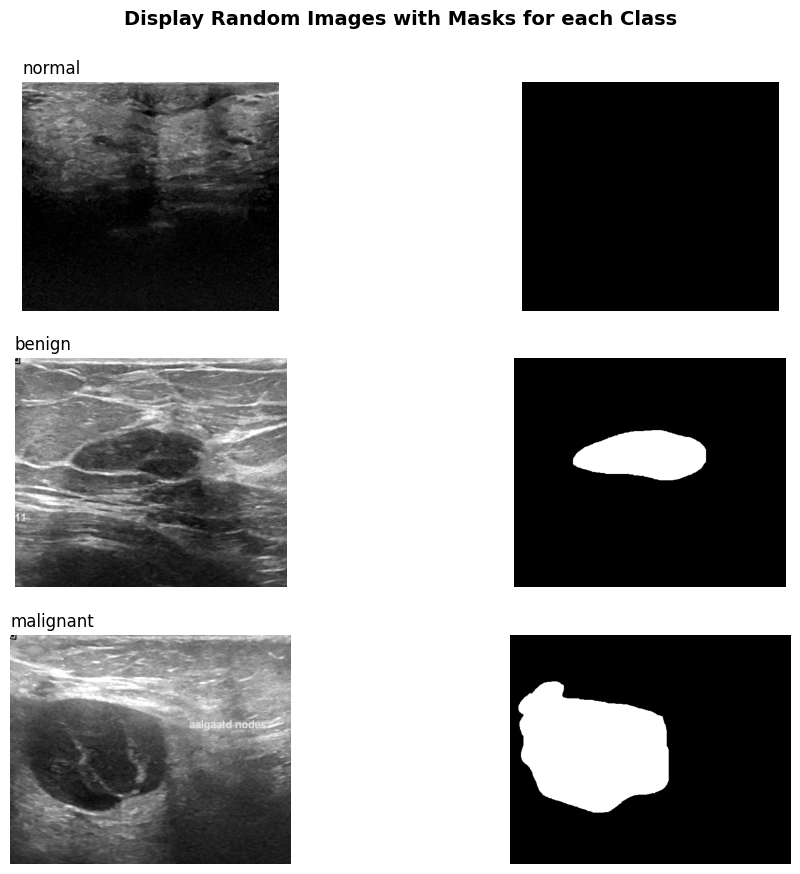

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

def display_random_images_with_masks(df, num_samples):
    classes = df['labels'].unique()
    fig = plt.figure(figsize=(12, len(classes) * 3))
    plot_index = 1

    for cls in classes:
        class_images = df[df['labels'] == cls]
        sampled_images = class_images.sample(n=num_samples, replace=len(class_images) < num_samples)

        for i, (_, row) in enumerate(sampled_images.iterrows()):
            img = Image.open(row['images_path'])
            msk = Image.open(row['masks_path'])

            plt.subplot(len(classes) * num_samples, 2, plot_index)
            plt.imshow(img, cmap='gray')
            if i == 0:
                plt.title(cls, loc='left')
            plt.axis('off')
            plot_index += 1

            plt.subplot(len(classes) * num_samples, 2, plot_index)
            plt.imshow(msk, cmap='gray')
            plt.axis('off')
            plot_index += 1

    plt.tight_layout(pad=2)
    fig.suptitle('Display Random Images with Masks for each Class', fontsize=14, fontweight='bold')
    plt.subplots_adjust(top=0.9)
    plt.show()

# Example usage
display_random_images_with_masks(df, 1)


# **Preprocessing on DataSet**

In [13]:
import os
from sklearn.model_selection import train_test_split

def get_image_and_mask_paths(root_dir):
    image_paths = []
    mask_paths = []

    for class_dir in ['benign', 'malignant', 'normal']:
        class_path = os.path.join(root_dir, class_dir)
        for filename in os.listdir(class_path):
            if filename.endswith('.png') and '_mask' not in filename:
                image_path = os.path.join(class_path, filename)
                image_paths.append(image_path)

                # Find corresponding masks
                base_name = filename.split('.')[0]
                masks = []
                mask1_path = os.path.join(class_path, base_name + '_mask.png')
                mask2_path = os.path.join(class_path, base_name + '_mask_1.png')

                if os.path.exists(mask1_path):
                    masks.append(mask1_path)
                if os.path.exists(mask2_path):
                    masks.append(mask2_path)

                mask_paths.append(masks)

    return image_paths, mask_paths

data_dir = DATA_PATH
image_paths, mask_paths = get_image_and_mask_paths(data_dir)

print('Image paths:', image_paths)
print('Mask paths:', mask_paths)

print("Total images:", len(image_paths))
print("Total masks:", len(mask_paths))
print("Sample image:", image_paths[0])
print("Sample masks:",  mask_paths[0])

Image paths: ['Dataset_BUSI_with_GT/benign/benign (100).png', 'Dataset_BUSI_with_GT/benign/benign (106).png', 'Dataset_BUSI_with_GT/benign/benign (10).png', 'Dataset_BUSI_with_GT/benign/benign (1).png', 'Dataset_BUSI_with_GT/benign/benign (101).png', 'Dataset_BUSI_with_GT/benign/benign (105).png', 'Dataset_BUSI_with_GT/benign/benign (103).png', 'Dataset_BUSI_with_GT/benign/benign (102).png', 'Dataset_BUSI_with_GT/benign/benign (104).png', 'Dataset_BUSI_with_GT/benign/benign (124).png', 'Dataset_BUSI_with_GT/benign/benign (109).png', 'Dataset_BUSI_with_GT/benign/benign (128).png', 'Dataset_BUSI_with_GT/benign/benign (116).png', 'Dataset_BUSI_with_GT/benign/benign (136).png', 'Dataset_BUSI_with_GT/benign/benign (146).png', 'Dataset_BUSI_with_GT/benign/benign (11).png', 'Dataset_BUSI_with_GT/benign/benign (144).png', 'Dataset_BUSI_with_GT/benign/benign (14).png', 'Dataset_BUSI_with_GT/benign/benign (120).png', 'Dataset_BUSI_with_GT/benign/benign (135).png', 'Dataset_BUSI_with_GT/benign/be

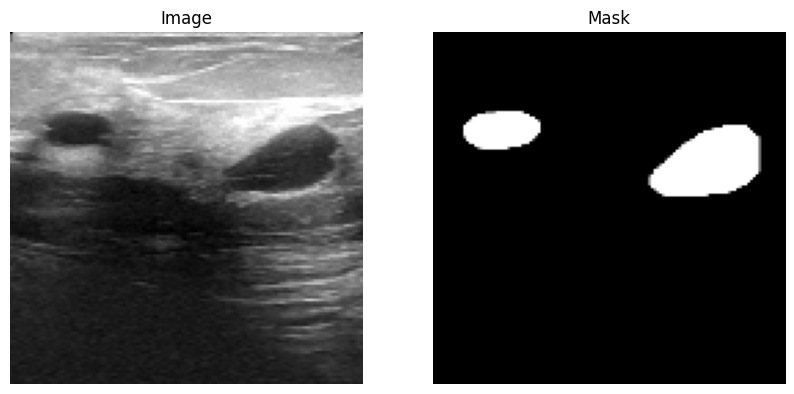

In [ ]:
# Example
import matplotlib.pyplot as plt

# Function to display an image and its mask
def display_image_and_mask(image_path, mask_paths, target_size):
    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    image = cv2.resize(image, target_size)
    image = image / 255.0

    combined_mask = np.zeros(target_size, dtype=np.float32)
    for mask_path in mask_paths:
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is None:
            print(f"Error: Unable to read mask file {mask_path}")
            continue
        mask = cv2.resize(mask, target_size)
        mask = mask / 255.0
        combined_mask = np.maximum(combined_mask, mask)

    # Display the image and its mask
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(image, cmap='gray')
    plt.title('Image')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(combined_mask, cmap='gray')
    plt.title('Mask')
    plt.axis('off')

    plt.show()

# Example usage
target_size = (128, 128)
image_path = image_paths[0]
mask_paths = mask_paths[0]
display_image_and_mask(image_path, mask_paths, target_size)


**Preprocessing**

In [14]:
# Apply Preprocessing

import numpy as np
import cv2

def load_data(image_paths, mask_paths, target_size):
    images = []
    masks = []

    for img_path, mask_list in zip(image_paths, mask_paths):
        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        image = cv2.resize(image, target_size)
        image = image / 255.0
        image = np.expand_dims(image, axis=-1)

        combined_mask = np.zeros(target_size, dtype=np.float32)
        for mask_path in mask_list:
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            mask = cv2.resize(mask, target_size)
            mask = mask / 255.0
            combined_mask = np.maximum(combined_mask, mask)

        combined_mask = np.expand_dims(combined_mask, axis=-1)

        images.append(image)
        masks.append(combined_mask)

    return np.array(images), np.array(masks)

# Example usage
target_size = (128, 128)

images, masks = load_data(image_paths, mask_paths, target_size )

# Check data shapes
print(f"Images shape: {images.shape}")
print(f"Masks shape: {masks.shape}")


Images shape: (780, 128, 128, 1)
Masks shape: (780, 128, 128, 1)


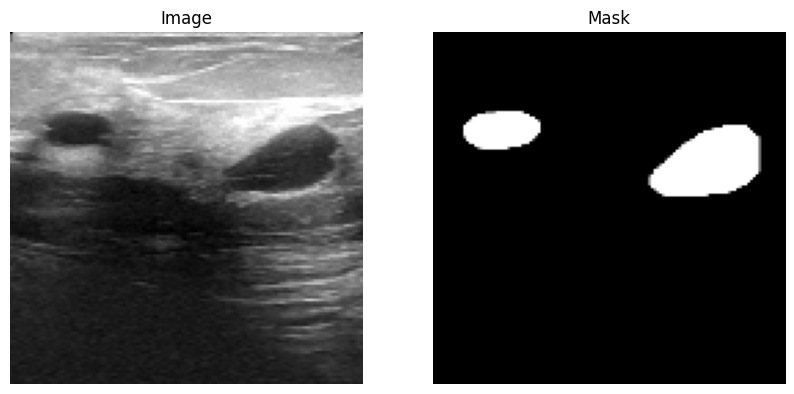

In [ ]:
import matplotlib.pyplot as plt

# Function to display an image and its mask
def display_image_and_mask(image, mask):
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(image.squeeze(), cmap='gray')
    plt.title('Image')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(mask.squeeze(), cmap='gray')
    plt.title('Mask')
    plt.axis('off')

    plt.show()

# Example usage
index = 0  # Index of the image and mask you want to display
display_image_and_mask(images[index], masks[index])


# **Split Data to Train, Test, Validation**

In [15]:
X_train, X_temp, y_train, y_temp = train_test_split(images, masks, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print(f"Training set: {X_train.shape}, {y_train.shape}")
print(f"Validation set: {X_val.shape}, {y_val.shape}")
print(f"Test set: {X_test.shape}, {y_test.shape}")

Training set: (546, 128, 128, 1), (546, 128, 128, 1)
Validation set: (117, 128, 128, 1), (117, 128, 128, 1)
Test set: (117, 128, 128, 1), (117, 128, 128, 1)


**SACE Method**

In [16]:
import cv2
import albumentations as A
from albumentations.core.transforms_interface import ImageOnlyTransform

def apply_sace(image, alpha=10, beta=0.4):
  class SACETransform(ImageOnlyTransform):
    def __init__(self, alpha, beta, always_apply=False, p=1.0):
      super().__init__(always_apply, p)
      self.alpha = alpha
      self.beta = beta

    def apply(self, image, **params):

      if len(image.shape) == 3 and image.shape[2] == 1:
        image = image.squeeze(axis=-1)
      elif len(image.shape) == 2:
        image = np.expand_dims(image, axis=-1)

      image = image.astype(np.float32)   # because images are normalized


      # Step1: Compute Intensity Variation Map
      blurred = cv2.GaussianBlur(image, (9, 9), 2)
      intensity_map = np.abs(image - blurred)

      # Step2: Apply Sigmoid Mapping
      sigmoid_map = 1 / (1 + np.exp(-self.alpha * (image - self.beta)))

      # Step3: Adaptive Contrast Enhancement
      enhanced_image = intensity_map * sigmoid_map
      enhanced_image = np.clip(sigmoid_map, 0, 1)

      return (enhanced_image * 255).astype(np.uint8)


    def get_transform_init_args_names(self):
      return ("alpha", "beta")

  transform = A.Compose([SACETransform(alpha, beta, p=1.0)])

  return transform(image=image)['image']

**Example**

(-0.5, 127.5, 127.5, -0.5)

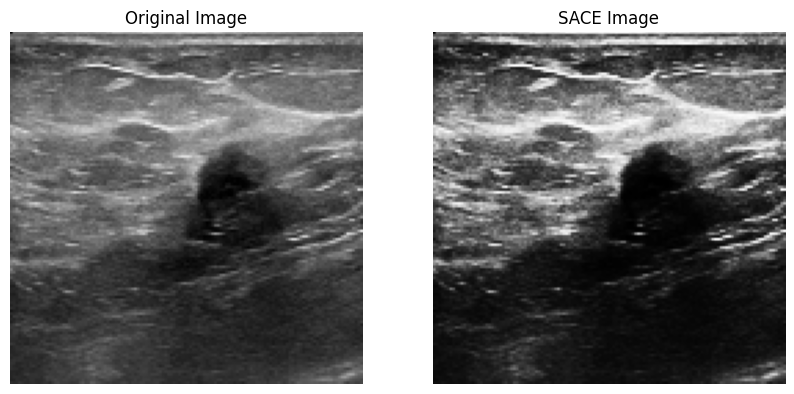

In [ ]:
img = X_train[5]
img_e = apply_sace(img)

index = 0  # Index of the image you want to display
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img.squeeze(), cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_e.squeeze(), cmap='gray')
plt.title('SACE Image')
plt.axis('off')

# **Apply SACE**

In [17]:
X_train_sace = [apply_sace(img) for img in X_train]

In [18]:
X_train_sace = np.array(X_train_sace).astype(np.float32) / 255.0
X_train_sace = np.expand_dims(X_train_sace, axis=-1)  # Add channel dimension

In [19]:
X_train_sace.shape

(546, 128, 128, 1)

**Display on One Sample**

(-0.5, 127.5, 127.5, -0.5)

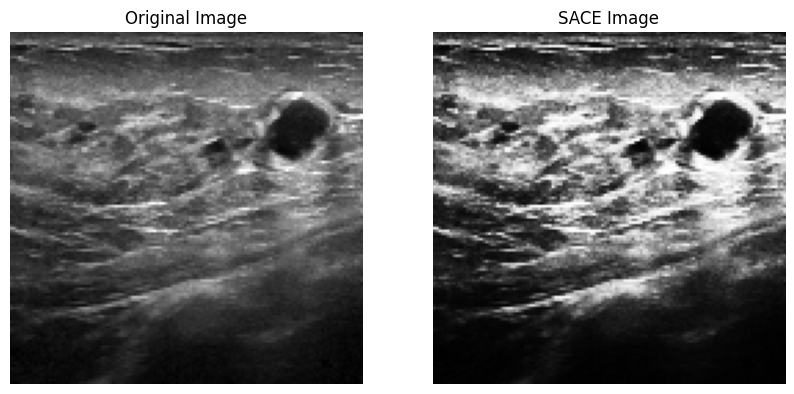

In [ ]:
img = X_train[0]
img_e = X_train_sace[0]

index = 0  # Index of the image you want to display
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img.squeeze(), cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_e.squeeze(), cmap='gray')
plt.title('SACE Image')
plt.axis('off')

# **Improved U-Net Model (batch_size=16, epoch=40)**

In [31]:
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose, concatenate, Input, BatchNormalization, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

In [32]:
# improved U-Net

def conv_block(input_tensor, num_filters):
  ''' Convolutional block: Two 3*3 convolutions with ReLU activations.'''
  x = Conv2D(num_filters, (3, 3), activation='relu', padding='same')(input_tensor)
  x = BatchNormalization()(x)
  x = Conv2D(num_filters, (3, 3), activation='relu', padding='same')(x)
  x = BatchNormalization()(x)
  return x

def encoder_block(input_tensor, num_filters, dropout_rate=0.3):
  ''' contracting path '''
  ''' Encoder block: Conv block followed by max pooling and dropout'''
  x = conv_block(input_tensor, num_filters)
  p = MaxPooling2D((2, 2))(x)
  p = Dropout(dropout_rate)(p)
  return x, p

def decoder_block(input_tensor, num_filters, skip_connection):
  ''' expansive path  '''
  ''' Decoder block: Upsampling, concatenation with skip connection, and conv block.'''
  x = Conv2DTranspose(num_filters, (2, 2), strides=(2, 2), padding='same')(input_tensor)
  x = concatenate([x, skip_connection])
  x = conv_block(x, num_filters)
  return x

def build_unet(input_shape):
  ''' Build the U-Net model. '''
  inputs = Input(input_shape)

  # Encoder (contracting path)
  c1, p1 = encoder_block(inputs, 64)
  c2, p2 = encoder_block(p1, 128)
  c3, p3 = encoder_block(p2, 256)
  c4, p4 = encoder_block(p3, 512)

  # Bottleneck
  b1 = conv_block(p4, 1024)

  # Decoder (expanding path)
  u1 = decoder_block(b1, 512, c4)
  u2 = decoder_block(u1, 256, c3)
  u3 = decoder_block(u2, 128, c2)
  u4 = decoder_block(u3, 64, c1)

  # Output layer
  outputs = Conv2D(1, (1, 1), activation='sigmoid')(u4)

  model = Model(inputs, outputs, name='unet')
  return model

input_shape = (128, 128, 1)
model = build_unet(input_shape)
model.summary()

Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 128, 128, 1)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d (Conv2D)           │ (None, 128, 128, 64)   │            640 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization       │ (None, 128, 128, 64)   │            256 │ conv2d[0][0]           │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_1 (Conv2D)         │ (None, 128, 128, 64)   │         36,928 │ batch_normalization[0… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_1     │ (None, 128, 128, 64)   │            256 │ conv2d_1[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d             │ (None, 64, 64, 64)     │              0 │ batch_normalization_1… │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout (Dropout)         │ (None, 64, 64, 64)     │              0 │ max_pooling2d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_2 (Conv2D)         │ (None, 64, 64, 128)    │         73,856 │ dropout[0][0]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_2     │ (None, 64, 64, 128)    │            512 │ conv2d_2[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_3 (Conv2D)         │ (None, 64, 64, 128)    │        147,584 │ batch_normalization_2… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_3     │ (None, 64, 64, 128)    │            512 │ conv2d_3[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_1           │ (None, 32, 32, 128)    │              0 │ batch_normalization_3… │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_1 (Dropout)       │ (None, 32, 32, 128)    │              0 │ max_pooling2d_1[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_4 (Conv2D)         │ (None, 32, 32, 256)    │        295,168 │ dropout_1[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_4     │ (None, 32, 32, 256)    │          1,024 │ conv2d_4[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_5 (Conv2D)         │ (None, 32, 32, 256)    │        590,080 │ batch_normalization_4… │
├──────────────────────

 Total params: 31,054,145 (118.46 MB)

 Trainable params: 31,042,369 (118.42 MB)

 Non-trainable params: 11,776 (46.00 KB)

In [ ]:
from tensorflow.keras.metrics import MeanIoU

batch_size = 16
epochs = 40

#optimizer=Adam(learning_rate=0.001)
optimizer = 'adam'

model.compile(optimizer=optimizer,
              loss='binary_crossentropy',
              metrics=['accuracy', MeanIoU(num_classes=2, name='IoU')])

es = EarlyStopping(monitor='val_loss',
                   patience=5,
                   restore_best_weights=True)


history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=batch_size,
    epochs=epochs,
    #callbacks=[es]
)

Epoch 1/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 54s 857ms/step - IoU: 0.4635 - accuracy: 0.9444 - loss: 0.1534 - val_IoU: 0.4846 - val_accuracy: 0.6949 - val_loss: 1.3797
Epoch 2/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 9s 253ms/step - IoU: 0.4626 - accuracy: 0.9504 - loss: 0.1378 - val_IoU: 0.5234 - val_accuracy: 0.7865 - val_loss: 0.8624
Epoch 3/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 10s 256ms/step - IoU: 0.4616 - accuracy: 0.9503 - loss: 0.1357 - val_IoU: 0.5089 - val_accuracy: 0.8854 - val_loss: 0.4660
Epoch 4/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 10s 253ms/step - IoU: 0.4618 - accuracy: 0.9504 - loss: 0.1371 - val_IoU: 0.4967 - val_accuracy: 0.6849 - val_loss: 1.0611
Epoch 5/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 9s 251ms/step - IoU: 0.4607 - accuracy: 0.9561 - loss: 0.1154 - val_IoU: 0.4717 - val_accuracy: 0.9133 - val_loss: 0.2673
Epoch 6/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 11s 279ms/step - IoU: 0.4594 - accuracy: 0.9572 - loss: 0.1161 - val_IoU: 0.4606 - val_accuracy: 0.8774 - val_loss: 0.2987
Epoch 7/40
35/35 ━━━━━━━━━━━━━━━━━━━

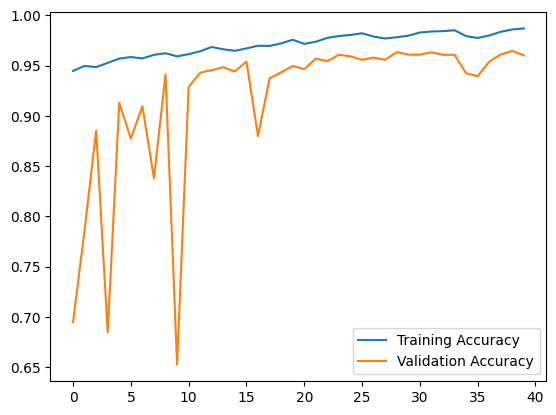

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


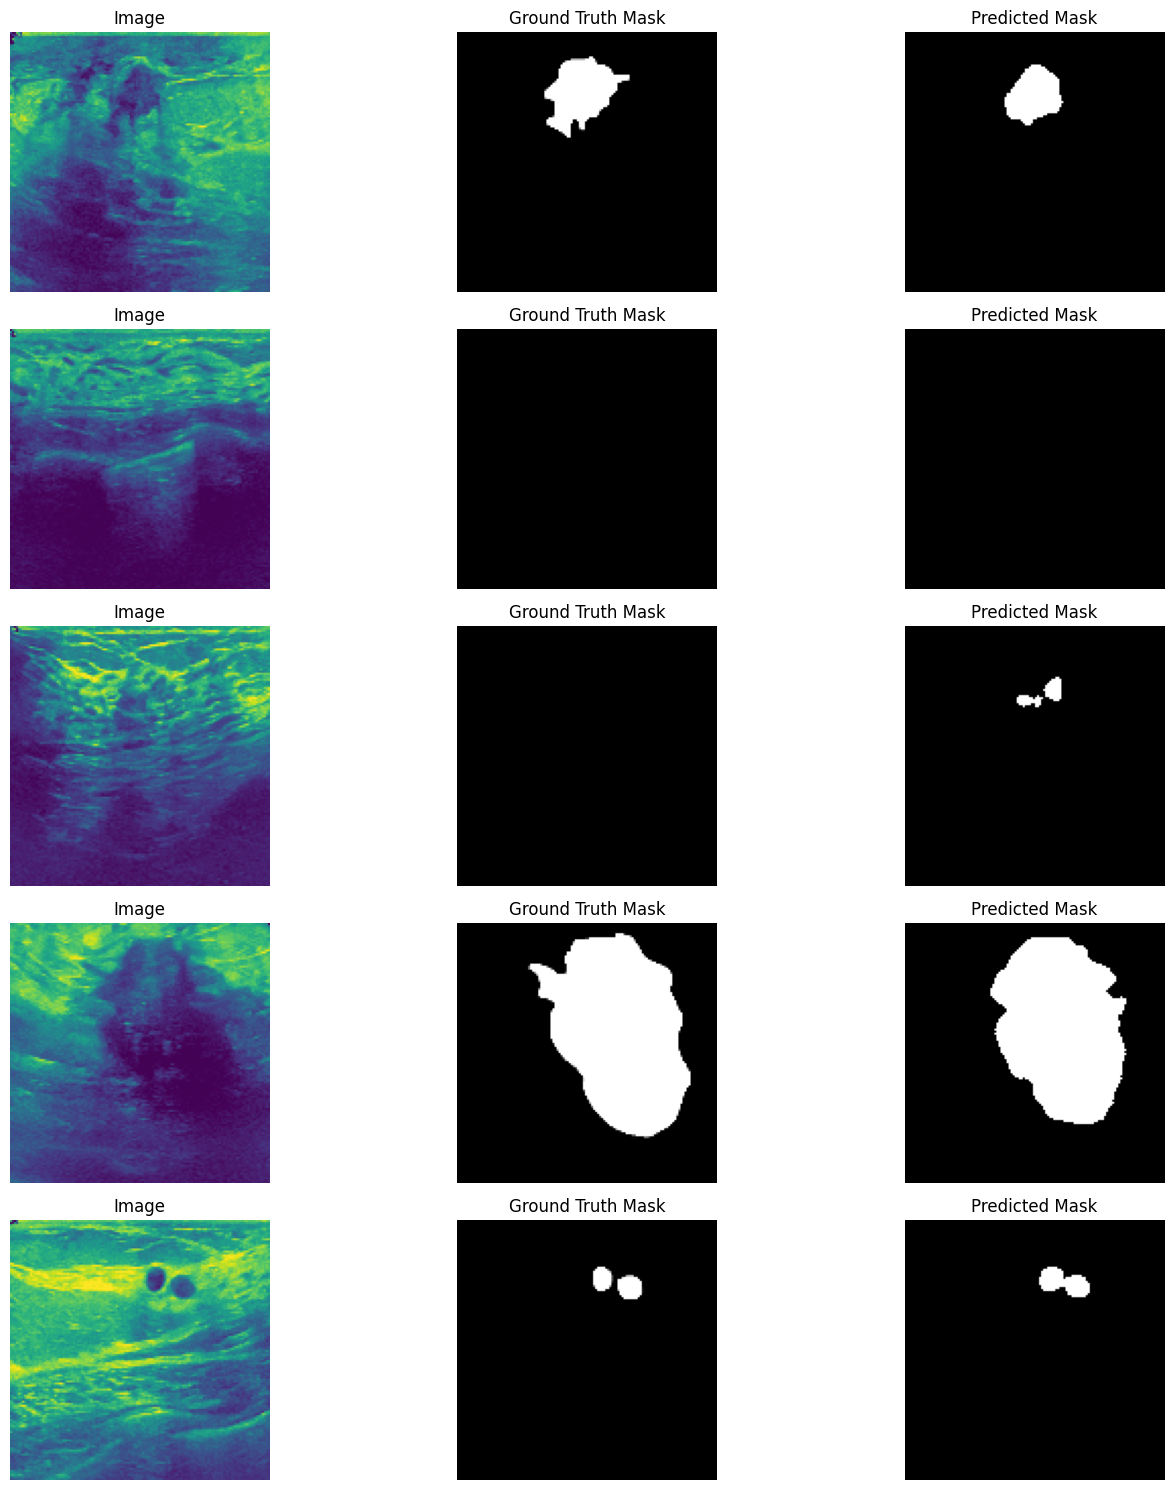

In [ ]:
# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.show()

# Save the model
model.save('/content/drive/My Drive/filoger/project/Models/unet.h5')

# Test model on multiple samples
threshold = 0.3  # Threshold to make predicted mask binary

# Select 5 samples for visualization
num_samples = 5
samples = X_test[:num_samples]
true_masks = y_test[:num_samples]
predicted_masks = model.predict(samples)



plt.figure(figsize=(15, num_samples * 3))
for i in range(num_samples):
    plt.subplot(num_samples, 3, i * 3 + 1)
    plt.title('Image')
    plt.imshow(samples[i])
    plt.axis('off')

    plt.subplot(num_samples, 3, i * 3 + 2)
    plt.title('Ground Truth Mask')
    plt.imshow(true_masks[i], cmap='gray')
    plt.axis('off')

    # Apply threshold to predicted mask
    binary_mask = (predicted_masks[i] > threshold).astype(np.uint8)

    plt.subplot(num_samples, 3, i * 3 + 3)
    plt.title('Predicted Mask')
    plt.imshow(binary_mask, cmap='gray')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [33]:
from tensorflow.keras.models import load_model

model_unet = load_model('/content/drive/My Drive/filoger/project/Models/unet.h5')
results = model_unet.evaluate(X_test, y_test)
print(f"Test Accuracy(unet): {results[1]}")

def dice_coefficient(y_true, y_pred, smooth=1e-6):

  y_true = y_true.flatten()
  y_pred = y_pred.flatten()

  intersection = np.sum(y_true * y_pred)
  union = np.sum(y_true) + np.sum(y_pred)
  dice = (2. * intersection + smooth) / (union + smooth)
  return dice


predictions = model_unet.predict(X_test)
predictions = (predictions > 0.3).astype(np.float32)

dice_scores = []
for i in range(len(X_test)):
  dice = dice_coefficient(y_test[i], predictions[i])
  dice_scores.append(dice)

average_dice = np.mean(dice_scores)
print(f'Average Dice Coefficient: {average_dice}')

4/4 ━━━━━━━━━━━━━━━━━━━━ 58s 13s/step - IoU: 0.4654 - accuracy: 0.9580 - loss: 0.1502
Test Accuracy(unet): 0.96112060546875
4/4 ━━━━━━━━━━━━━━━━━━━━ 61s 14s/step
Average Dice Coefficient: 0.7293176696039455


In [41]:
model_unet = load_model('/content/drive/My Drive/filoger/project/Models/unet.h5')

def iou(y_true, y_pred, smooth=1e-6):

  y_true = y_true.flatten()
  y_pred = y_pred.flatten()

  intersection = np.sum(y_true * y_pred)
  union = np.sum(y_true) + np.sum(y_pred) - intersection
  iou = (intersection + smooth) / (union + smooth)
  return iou


predictions = model_unet.predict(X_test)
predictions = (predictions > 0.3).astype(np.float32)

iou_scores = []
for i in range(len(X_test)):
  iou_score = iou(y_test[i], predictions[i])
  iou_scores.append(iou_score)

average_iou = np.mean(iou_scores)
print(f'Average IOU: {average_iou:.4f}')

4/4 ━━━━━━━━━━━━━━━━━━━━ 59s 14s/step
Average IOU: 0.6486


# **Improved U-Net Model (SACE) (batch_size=16, epoch=40)**

In [ ]:
# Improved U-Net_sace

def conv_block(input_tensor, num_filters):
  ''' Convolutional block: Two 3*3 convolutions with ReLU activations.'''
  x = Conv2D(num_filters, (3, 3), activation='relu', padding='same')(input_tensor)
  x = BatchNormalization()(x)
  x = Conv2D(num_filters, (3, 3), activation='relu', padding='same')(x)
  x = BatchNormalization()(x)
  return x

def encoder_block(input_tensor, num_filters, dropout_rate=0.3):
  ''' contracting path '''
  ''' Encoder block: Conv block followed by max pooling and dropout'''
  x = conv_block(input_tensor, num_filters)
  p = MaxPooling2D((2, 2))(x)
  p = Dropout(dropout_rate)(p)
  return x, p

def decoder_block(input_tensor, num_filters, skip_connection):
  ''' expansive path  '''
  ''' Decoder block: Upsampling, concatenation with skip connection, and conv block.'''
  x = Conv2DTranspose(num_filters, (2, 2), strides=(2, 2), padding='same')(input_tensor)
  x = concatenate([x, skip_connection])
  x = conv_block(x, num_filters)
  return x

def build_unet(input_shape):
  ''' Build the U-Net model. '''
  inputs = Input(input_shape)

  # Encoder (contracting path)
  c1, p1 = encoder_block(inputs, 64)
  c2, p2 = encoder_block(p1, 128)
  c3, p3 = encoder_block(p2, 256)
  c4, p4 = encoder_block(p3, 512)

  # Bottleneck
  b1 = conv_block(p4, 1024)

  # Decoder (expanding path)
  u1 = decoder_block(b1, 512, c4)
  u2 = decoder_block(u1, 256, c3)
  u3 = decoder_block(u2, 128, c2)
  u4 = decoder_block(u3, 64, c1)

  # Output layer
  outputs = Conv2D(1, (1, 1), activation='sigmoid')(u4)

  model = Model(inputs, outputs, name='improved_unet_sace')
  return model

input_shape = (128, 128, 1)
model4 = build_unet(input_shape)
model4.summary()


Model: "improved_unet_sace"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_86            │ (None, 128, 128, 1)    │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_299 (Conv2D)       │ (None, 128, 128, 64)   │            640 │ input_layer_86[0][0]   │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_208   │ (None, 128, 128, 64)   │            256 │ conv2d_299[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_300 (Conv2D)       │ (None, 128, 128, 64)   │         36,928 │ batch_normalization_2… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_209   │ (None, 128, 128, 64)   │            256 │ conv2d_300[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_27          │ (None, 64, 64, 64)     │              0 │ batch_normalization_2… │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_25 (Dropout)      │ (None, 64, 64, 64)     │              0 │ max_pooling2d_27[0][0] │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_301 (Conv2D)       │ (None, 64, 64, 128)    │         73,856 │ dropout_25[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_210   │ (None, 64, 64, 128)    │            512 │ conv2d_301[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_302 (Conv2D)       │ (None, 64, 64, 128)    │        147,584 │ batch_normalization_2… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_211   │ (None, 64, 64, 128)    │            512 │ conv2d_302[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_28          │ (None, 32, 32, 128)    │              0 │ batch_normalization_2… │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_26 (Dropout)      │ (None, 32, 32, 128)    │              0 │ max_pooling2d_28[0][0] │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_303 (Conv2D)       │ (None, 32, 32, 256)    │        295,168 │ dropout_26[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_212   │ (None, 32, 32, 256)    │          1,024 │ conv2d_303[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_304 (Conv2D)  

 Total params: 31,054,145 (118.46 MB)

 Trainable params: 31,042,369 (118.42 MB)

 Non-trainable params: 11,776 (46.00 KB)

In [ ]:
from tensorflow.keras.metrics import MeanIoU

batch_size = 16
epochs = 40

#optimizer=Adam(learning_rate=0.001)
optimizer = 'adam'

model4.compile(optimizer=optimizer,
              loss='binary_crossentropy',
              metrics=['accuracy', MeanIoU(num_classes=2, name='IoU')])

es = EarlyStopping(monitor='val_loss',
                   patience=5,
                   restore_best_weights=True)


history = model4.fit(
    X_train_sace, y_train,
    validation_data=(X_val, y_val),
    batch_size=batch_size,
    epochs=epochs,
    #callbacks=[es]
)

Epoch 1/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 54s 739ms/step - IoU: 0.4682 - accuracy: 0.6904 - loss: 0.7381 - val_IoU: 0.0834 - val_accuracy: 0.0838 - val_loss: 203.2066
Epoch 2/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 9s 252ms/step - IoU: 0.4837 - accuracy: 0.9082 - loss: 0.4733 - val_IoU: 0.0397 - val_accuracy: 0.0793 - val_loss: 4946.7090
Epoch 3/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 10s 252ms/step - IoU: 0.5091 - accuracy: 0.9320 - loss: 0.3644 - val_IoU: 0.4604 - val_accuracy: 0.5941 - val_loss: 0.8945
Epoch 4/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 10s 253ms/step - IoU: 0.5330 - accuracy: 0.9394 - loss: 0.2749 - val_IoU: 0.4604 - val_accuracy: 0.5737 - val_loss: 0.8598
Epoch 5/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 10s 252ms/step - IoU: 0.5031 - accuracy: 0.9317 - loss: 0.2656 - val_IoU: 0.2129 - val_accuracy: 0.1515 - val_loss: 65.6292
Epoch 6/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 10s 252ms/step - IoU: 0.4910 - accuracy: 0.9393 - loss: 0.2214 - val_IoU: 0.4478 - val_accuracy: 0.4464 - val_loss: 3.2718
Epoch 7/40
35/35 ━━━━━━━━━━━━

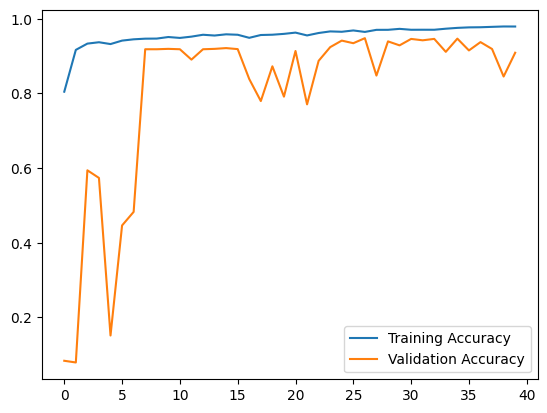

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


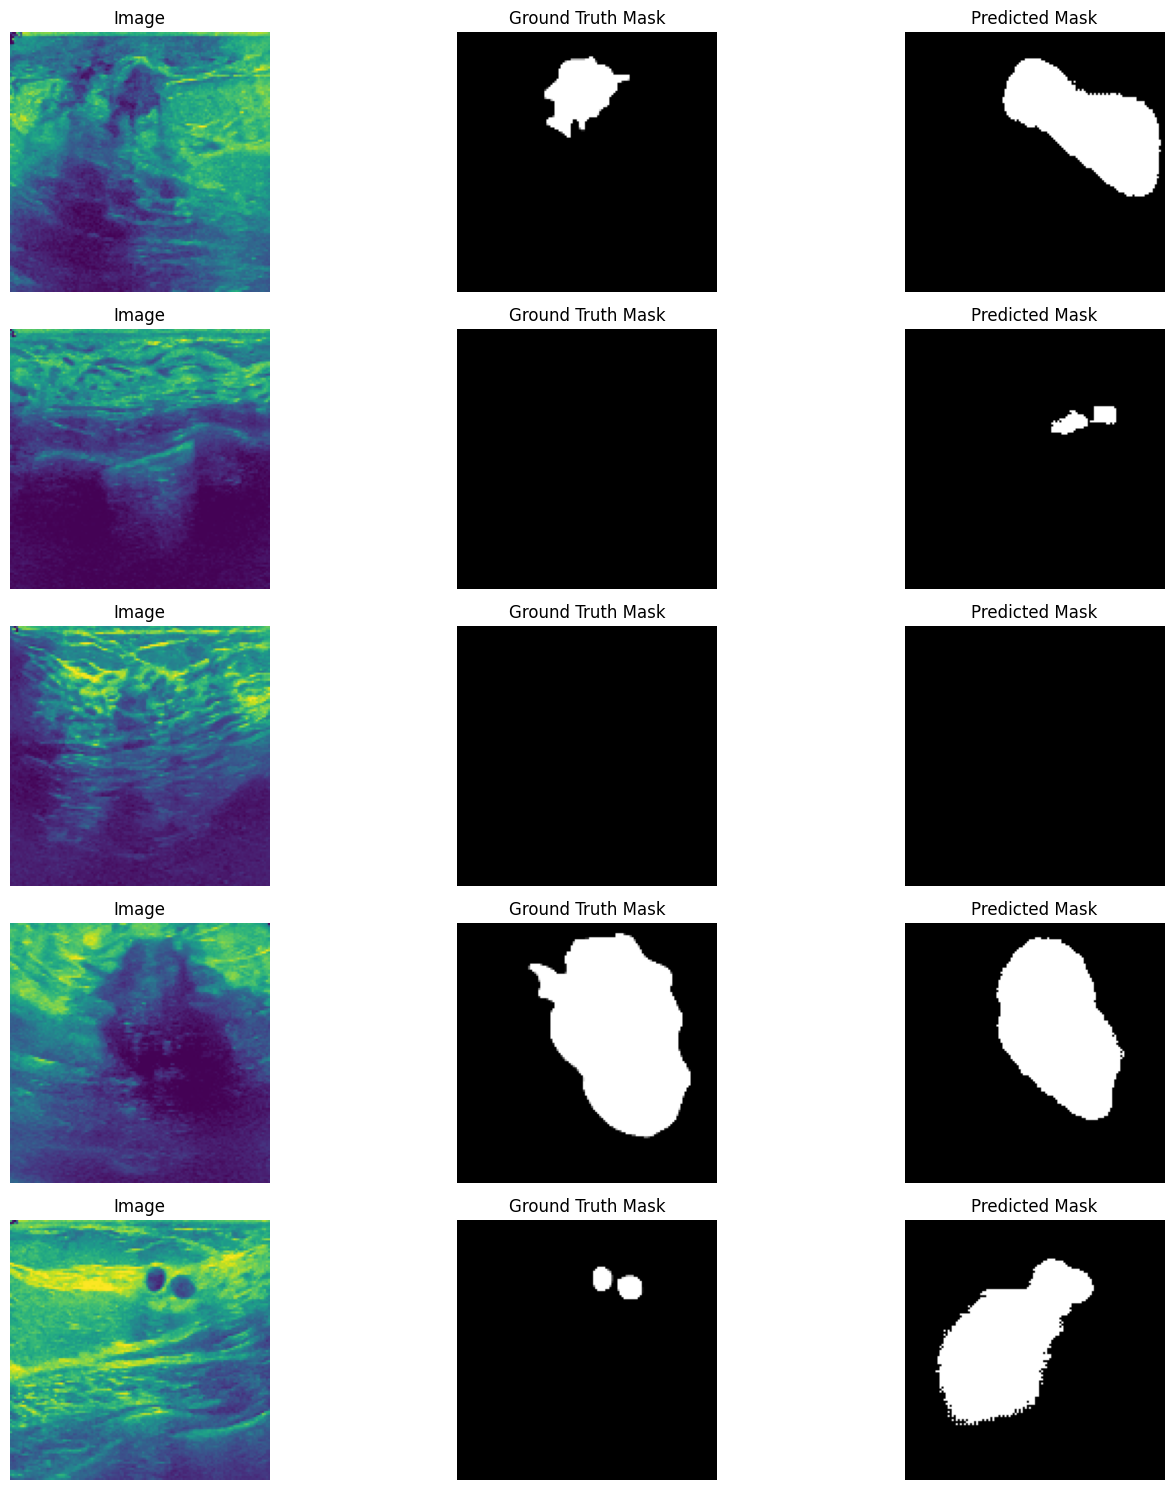

In [ ]:
#improved_unet_sace

# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.show()

# Save the model
model4.save('/content/drive/My Drive/filoger/project/Models/improved_unet_sace.h5')

# Test model on multiple samples
threshold = 0.3  # Threshold to make predicted mask binary

# Select 5 samples for visualization
num_samples = 5
samples = X_test[:num_samples]
true_masks = y_test[:num_samples]
predicted_masks = model4.predict(samples)



plt.figure(figsize=(15, num_samples * 3))
for i in range(num_samples):
    plt.subplot(num_samples, 3, i * 3 + 1)
    plt.title('Image')
    plt.imshow(samples[i])
    plt.axis('off')

    plt.subplot(num_samples, 3, i * 3 + 2)
    plt.title('Ground Truth Mask')
    plt.imshow(true_masks[i], cmap='gray')
    plt.axis('off')

    # Apply threshold to predicted mask
    binary_mask = (predicted_masks[i] > threshold).astype(np.uint8)

    plt.subplot(num_samples, 3, i * 3 + 3)
    plt.title('Predicted Mask')
    plt.imshow(binary_mask, cmap='gray')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [35]:
from tensorflow.keras.models import load_model

model_improved_unet_sace = load_model('/content/drive/My Drive/filoger/project/Models/improved_unet_sace.h5')
results = model_improved_unet_sace.evaluate(X_test, y_test)
print(f"Test Accuracy(unet): {results[1]}")

def dice_coefficient(y_true, y_pred, smooth=1e-6):

  y_true = y_true.flatten()
  y_pred = y_pred.flatten()

  intersection = np.sum(y_true * y_pred)
  union = np.sum(y_true) + np.sum(y_pred)
  dice = (2. * intersection + smooth) / (union + smooth)
  return dice


predictions = model_improved_unet_sace.predict(X_test)
predictions = (predictions > 0.3).astype(np.float32)

dice_scores = []
for i in range(len(X_test)):
  dice = dice_coefficient(y_test[i], predictions[i])
  dice_scores.append(dice)

average_dice = np.mean(dice_scores)
print(f'Average Dice Coefficient: {average_dice}')

4/4 ━━━━━━━━━━━━━━━━━━━━ 57s 13s/step - IoU: 0.4890 - accuracy: 0.8992 - loss: 0.3985
Test Accuracy(unet): 0.8990781307220459
4/4 ━━━━━━━━━━━━━━━━━━━━ 59s 14s/step
Average Dice Coefficient: 0.41778630600491357


In [44]:
model_improved_unet_sace = load_model('/content/drive/My Drive/filoger/project/Models/improved_unet_sace.h5')

def iou(y_true, y_pred, smooth=1e-6):

  y_true = y_true.flatten()
  y_pred = y_pred.flatten()

  intersection = np.sum(y_true * y_pred)
  union = np.sum(y_true) + np.sum(y_pred) - intersection
  iou = (intersection + smooth) / (union + smooth)
  return iou


predictions = model_improved_unet_sace.predict(X_test)
predictions = (predictions > 0.3).astype(np.float32)

iou_scores = []
for i in range(len(X_test)):
  iou_score = iou(y_test[i], predictions[i])
  iou_scores.append(iou_score)

average_iou = np.mean(iou_scores)
print(f'Average IOU: {average_iou:.4f}')

4/4 ━━━━━━━━━━━━━━━━━━━━ 59s 14s/step
Average IOU: 0.3230
